# Практическая работа № 3
## Классификация самолётов по фотографии с помощью мультимодальных языковых моделей

**Группа № 4**

- Гусев Алексей Дмитриевич
- Дворников Петр Михайлович
- Еникеев Дамир Илмирович
- Майоров Егор Александрович

**Дата эксперимента:** 24 октября 2026 года.  
**Среда выполнения:** Google Colab, NVIDIA Tesla T4.  
**Объём:** 30 фотографий, 2 модели, 60 предсказаний.

## 1. Цель и постановка задачи

Цель работы — сравнить две мультимодальные языковые модели в задаче бинарной классификации самолётов по фотографиям.
Модели **SmolVLM-500M-Instruct** и **Qwen2.5-VL-3B-Instruct** получают изображение и текстовую инструкцию,
после чего выбирают один из классов: `military` или `civilian`.

Для выполнения работы сформирована небольшая выборка с нетривиальными случаями, проведён одинаковый
протокол обработки, рассчитаны метрики качества и исследованы ошибки. Обучение и дообучение моделей не выполнялись.

## 2. Выборка и правила разметки

Эталонная метка определяется **основным назначением изображённой модификации самолёта**.
Принадлежность конкретного борта военному оператору сама по себе не изменяет назначение гражданской конструкции.

| Класс | Содержание | Контрольные случаи | Сложные случаи | Всего |
|---|---|---:|---:|---:|
| Военный (`military`) | Боевые, военные учебные, транспортные, патрульные самолёты и заправщики | 5 | 10 | 15 |
| Гражданский (`civilian`) | Пассажирские, грузовые, частные, спортивные, сельскохозяйственные и пожарные самолёты | 5 | 10 | 15 |
| **Итого** | | **10** | **20** | **30** |

Сложность задана до получения ответов моделей. В выборку включены заправщики и патрульные самолёты
на базе гражданских платформ, военные транспорты без видимого вооружения, гражданский L-100 Hercules,
пилотажные самолёты и специальные грузовые конструкции.

Фотографии отобраны из Wikipedia и Wikimedia Commons. Для каждого файла сохранены авторство, лицензия,
ссылка на источник и SHA-256. Все 30 фотографий визуально проверены вместе с описаниями источников.
На фотографиях дозаправки № 09 и № 10 классифицируется самый крупный основной самолёт.

### Состав выборки

| № | Самолёт | Эталон | Тип случая | Причина включения |
|---:|---|---|---|---|
| 01 | General Dynamics F-16 Fighting Falcon | Военный | Контрольный | Типичный истребитель |
| 02 | Sukhoi Su-27 | Военный | Контрольный | Типичный истребитель |
| 03 | Lockheed Martin F-35 Lightning II | Военный | Контрольный | Типичный истребитель |
| 04 | Northrop B-2 Spirit | Военный | Контрольный | Бомбардировщик необычной формы |
| 05 | Fairchild Republic A-10 Thunderbolt II | Военный | Контрольный | Штурмовик |
| 06 | Boeing C-17 Globemaster III | Военный | Сложный | Военный транспорт без вооружения |
| 07 | Lockheed C-5 Galaxy | Военный | Сложный | Крупный транспорт похож на гражданский грузовой |
| 08 | Airbus A400M Atlas | Военный | Сложный | Турбовинтовой транспорт |
| 09 | Boeing KC-135 Stratotanker | Военный | Сложный | Заправщик похож на авиалайнер |
| 10 | Airbus A330 MRTT | Военный | Сложный | Военная версия гражданской платформы |
| 11 | Boeing P-8 Poseidon | Военный | Сложный | Патрульный на базе Boeing 737 |
| 12 | Boeing E-3 Sentry | Военный | Сложный | ДРЛО на базе авиалайнера |
| 13 | Beechcraft T-6 Texan II | Военный | Сложный | Учебный похож на гражданский |
| 14 | Pilatus PC-21 | Военный | Сложный | Военный учебный |
| 15 | Alenia C-27J Spartan | Военный | Сложный | Небольшой транспорт |
| 16 | Airbus A380 | Гражданский | Контрольный | Пассажирский авиалайнер |
| 17 | Boeing 787 Dreamliner | Гражданский | Контрольный | Пассажирский авиалайнер |
| 18 | Airbus A350 | Гражданский | Контрольный | Пассажирский авиалайнер |
| 19 | Embraer E-Jet family | Гражданский | Контрольный | Региональный пассажирский |
| 20 | Cirrus SR22 | Гражданский | Контрольный | Частный поршневой |
| 21 | Lockheed L-100 Hercules | Гражданский | Сложный | Гражданская версия военного транспорта |
| 22 | Canadair CL-415 | Гражданский | Сложный | Пожарная амфибия |
| 23 | Air Tractor AT-802 | Гражданский | Сложный | Базовый сельскохозяйственный, не AT-802U |
| 24 | Extra EA-300 | Гражданский | Сложный | Пилотажный самолёт |
| 25 | Sukhoi Su-26 | Гражданский | Сложный | Спортивный самолёт марки военных истребителей |
| 26 | Bede BD-5 | Гражданский | Сложный | Спортивный, необычный силуэт |
| 27 | Pilatus PC-12 | Гражданский | Сложный | Гражданский тип со специальными операторами |
| 28 | Piaggio P.180 Avanti | Гражданский | Сложный | Необычная компоновка |
| 29 | Airbus Beluga | Гражданский | Сложный | Специальный грузовой |
| 30 | Boeing Dreamlifter | Гражданский | Сложный | Крупногабаритный грузовой |

## 3. Модели и вычислительная среда

| Характеристика | SmolVLM-500M-Instruct | Qwen2.5-VL-3B-Instruct |
|---|---|---|
| Семейство | SmolVLM / Idefics3 | Qwen2.5-VL |
| Заявленный размер | 500M | 3B |
| Вход | Изображение и текст | Изображение и текст |
| Источник | Hugging Face Hub | Hugging Face Hub |
| Формат вычислений | float16 | float16 |
| Механизм внимания | SDPA | SDPA |

Модели выполнялись последовательно на одной NVIDIA Tesla T4. После обработки выборки первой моделью
память освобождалась перед загрузкой второй. Использованы Python 3.13.16, PyTorch 2.11.0+cu130,
Transformers 4.57.1, Accelerate 1.10.1 и Pillow 11.3.0.

Точные версии моделей закреплены SHA коммитов в `config.json`; сведения о выполнении сохранены в `results/experiment.json`.
Модели загружены из Hugging Face Hub и выполнялись непосредственно в среде Colab.

## 4. Протокол эксперимента

Для обеих моделей использовались одни и те же изображения и одна инструкция. Название самолёта,
URL источника и эталонная метка в запрос не включались. Применялся zero-shot режим без примеров ответов.

Исходные JPEG ограничивались по длинной стороне 768 пикселями. Затем применялись штатные процессоры моделей:
у SmolVLM параметр `longest_edge=1024`, у Qwen — `min_pixels=256×28²` и `max_pixels=512×28²`.
Использовалась генерация без случайного выбора (`do_sample=False`), максимум 16 новых токенов и seed=42.

### Инструкция моделям

> Classify the largest, primary aircraft in this photo. Use the main intended role of its aircraft variant, not only its operator. Military includes fighters, military trainers, transports, tankers and patrol aircraft. Civilian includes passenger, civilian cargo, private, sport, agricultural and firefighting aircraft. Reply with exactly one word: military or civilian.

При обработке ответа игнорировались регистр, внешние кавычки и завершающая точка. Прочие ответы
получали метку `invalid` и учитывались как ошибки. Декодировались только новые токены, без текста входной инструкции.
Каждое предсказание сохранялось сразу после получения.

### Метрики

- **Accuracy** — доля правильных ответов.
- **Precision** — доля правильных ответов среди предсказаний данного класса.
- **Recall** — доля найденных объектов данного класса.
- **F1** — гармоническое среднее precision и recall; **macro-F1** — среднее F1 двух классов.
- **Accuracy на сложных случаях** — доля правильных ответов на 20 заранее выделенных фотографиях.
- **Coverage** — доля ответов в допустимом формате.

Среднее и медианное время включают обработку изображения и генерацию ответа, но не загрузку модели
и весов из интернета. GPU синхронизировался до и после измерения.

## 5. Результаты

Эксперимент завершён: получены 60 уникальных ответов, по 30 на каждую модель.
Оба набора ответов относятся к одному протоколу и одной зафиксированной выборке.

### 5.1. Основные показатели

| Модель | Верно | Accuracy | Precision macro | Recall macro | Macro-F1 |
|---|---:|---:|---:|---:|---:|
| Qwen2.5-VL-3B | 29/30 | 96,67% | 0,969 | 0,967 | 0,967 |
| SmolVLM-500M | 15/30 | 50,00% | 0,250 | 0,500 | 0,333 |

Qwen2.5-VL-3B превысила SmolVLM-500M по accuracy на **46,67 процентного пункта**.
Обе модели вернули ответы допустимого формата во всех случаях: **coverage = 100%**.

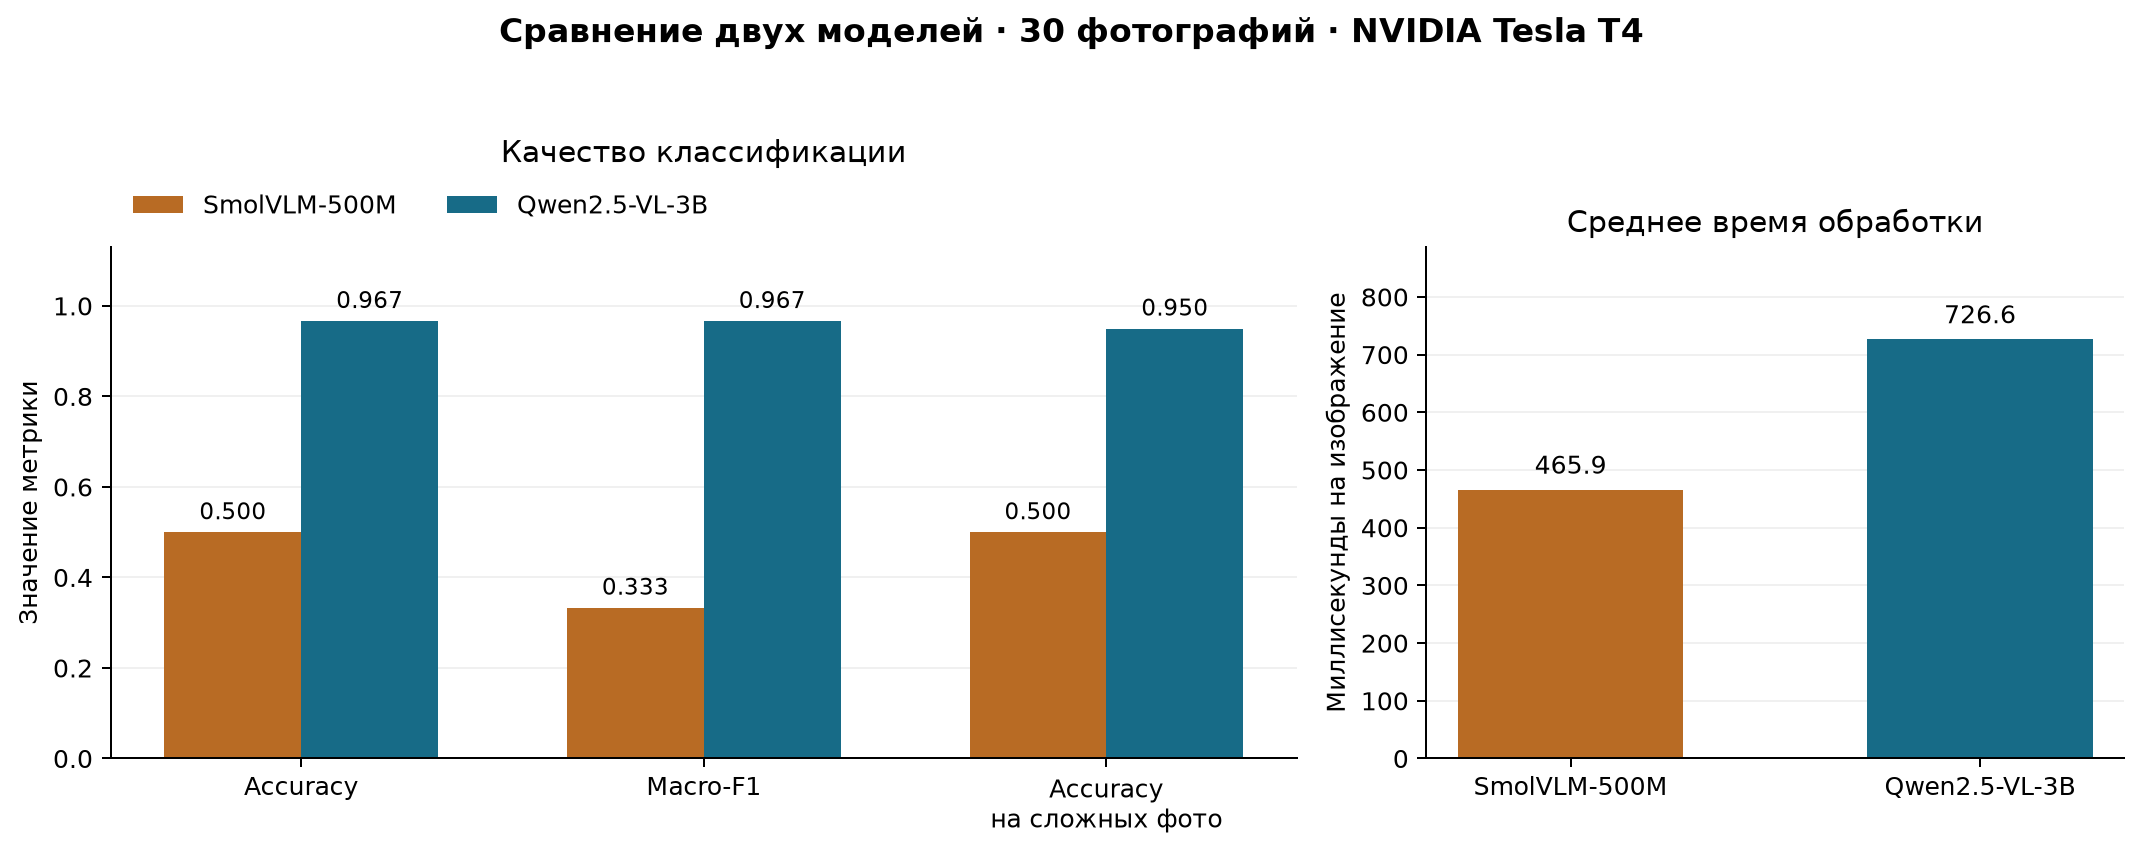

In [ ]:
from IPython.display import Image, display

display(
    Image(
        url=(
            "https://raw.githubusercontent.com/"
            "Youdzter-Utka/ISIT-work-3/main/results/"
            "comparison.png"
        )
    )
)

### 5.2. Сложные случаи и время обработки

| Показатель | SmolVLM-500M | Qwen2.5-VL-3B |
|---|---:|---:|
| Верно на сложных фото | 10 из 20 | 19 из 20 |
| Accuracy на сложных фото | 50,00% | 95,00% |
| Среднее время, с/фото | 0,466 | 0,727 |
| Медианное время, с/фото | 0,362 | 0,691 |
| Сумма измеренного времени обработки 30 фото, с | 13,976 | 21,799 |

SmolVLM-500M обрабатывала изображения быстрее, однако преимущество по времени сопровождалось
существенно более низким качеством классификации. Время первого примера может включать эффект прогрева;
показатели времени относятся к данному запуску на Tesla T4.

### 5.3. Показатели по классам

| Модель | Класс | Precision | Recall | F1 | Число фото |
|---|---|---:|---:|---:|---:|
| SmolVLM-500M | Военный | 0,500 | 1,000 | 0,667 | 15 |
| SmolVLM-500M | Гражданский | 0,000 | 0,000 | 0,000 | 15 |
| Qwen2.5-VL-3B | Военный | 0,938 | 1,000 | 0,968 | 15 |
| Qwen2.5-VL-3B | Гражданский | 1,000 | 0,933 | 0,966 | 15 |

### 5.4. Матрицы ошибок

Строки показывают эталонный класс, столбцы — ответ модели. Третий столбец отражает невалидные ответы;
в данном эксперименте их не было.

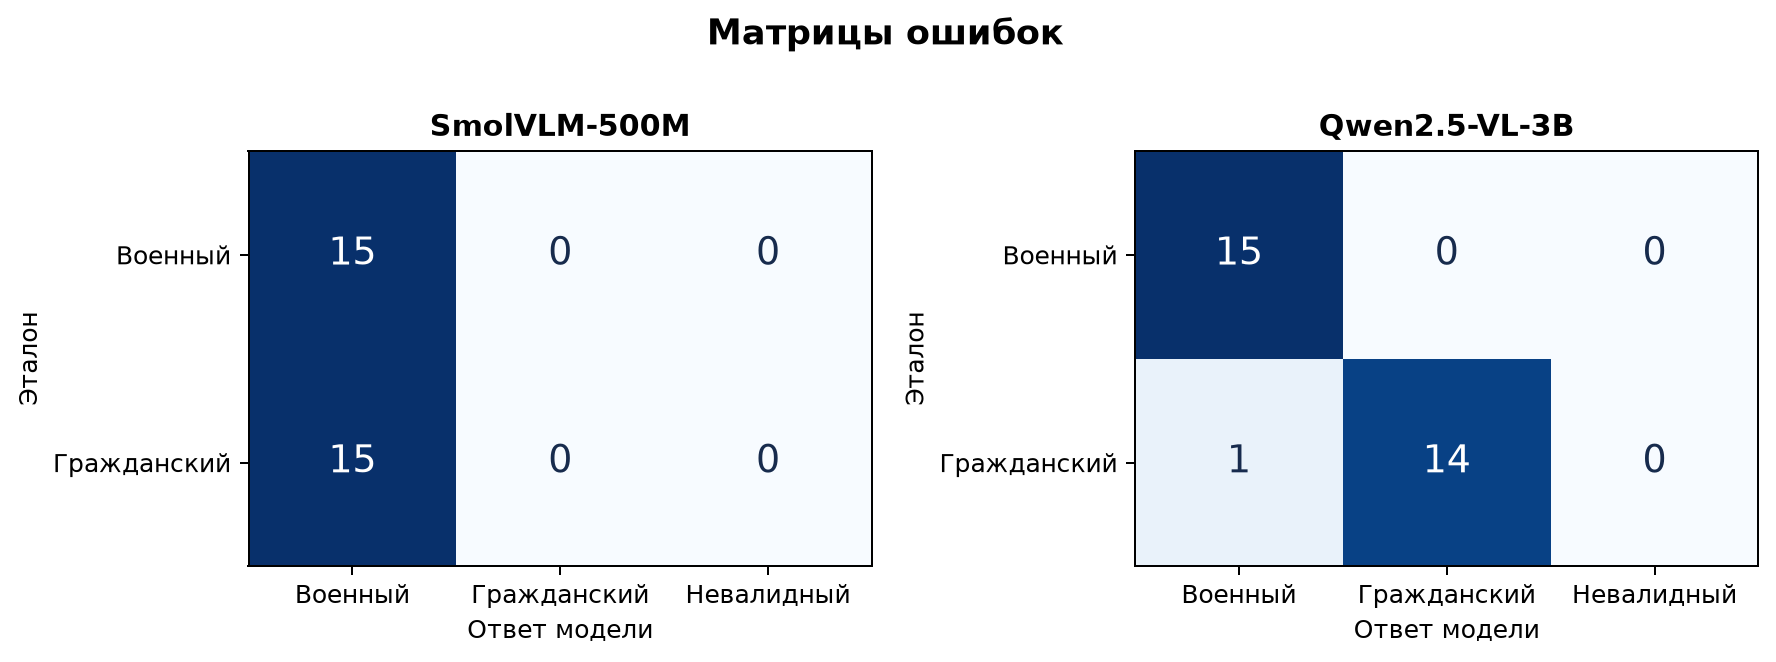

In [ ]:
from IPython.display import Image, display

display(
    Image(
        url=(
            "https://raw.githubusercontent.com/"
            "Youdzter-Utka/ISIT-work-3/main/results/"
            "confusion_matrices_ru.png"
        )
    )
)

## 6. Анализ ошибок

### SmolVLM-500M: выбор одного класса

На всех 30 фотографиях модель сформировала ответ `Military.`. Она правильно определила 15 военных
самолётов и ошиблась на всех 15 гражданских. Поэтому accuracy=50% совпадает с результатом постоянного
классификатора, который всегда выбирает один класс на сбалансированной выборке.

Recall военного класса равен 1,000, но recall гражданского класса равен 0,000. Следовательно,
в условиях данного протокола модель не различала два класса. Доля валидных ответов 100% характеризует
соблюдение формата, а не качество распознавания.

### Qwen2.5-VL-3B: Lockheed L-100 Hercules

Модель верно классифицировала все 15 военных и 14 из 15 гражданских самолётов. Единственная ошибка — фото № 21:

| Объект | Эталон | Ответ Qwen | Тип случая |
|---|---|---|---|
| Lockheed L-100 Hercules | Гражданский | Военный | Сложный |

L-100 является гражданской модификацией транспортного самолёта семейства Hercules. На выбранной фотографии
самолёт связан с военным оператором и имеет характерный облик платформы военного транспортника.
Эти признаки могли повлиять на ответ, но по одному выходному слову установить внутреннюю причину ошибки нельзя.
Согласно принятому правилу разметки гражданское назначение модификации имеет приоритет перед оператором.

![Lockheed L-100 Hercules](https://raw.githubusercontent.com/Youdzter-Utka/ISIT-work-3/main/data/images/21.jpg)

Фото № 21. [Источник и лицензия](https://commons.wikimedia.org/wiki/File:Lockheed_L100-30_Hercules_HZ-128_(6819452647).jpg).

### Парное сравнение

На 14 фотографиях Qwen ответила верно, а SmolVLM ошиблась. Обратных случаев не было.
Точный двусторонний тест Мак-Немара дал **p = 0,000122**.
Результат указывает на различие правильности ответов в пределах данного парного эксперимента;
целевая выборка из 30 фото не позволяет автоматически распространить вывод на все авиационные изображения.

## 7. Выводы

1. Проведена классификация 30 фотографий самолётов двумя мультимодальными языковыми моделями; сохранены 60 ответов.
2. **Qwen2.5-VL-3B показала лучший результат:** accuracy=96,67%, macro-F1=0,967 и 95,00% accuracy на сложных случаях.
3. **SmolVLM-500M получила accuracy=50,00% и macro-F1=0,333**, выбирая военный класс для всех фотографий.
4. Единственная ошибка Qwen связана с гражданским L-100 Hercules — нетривиальным примером визуального сходства гражданской и военной модификаций.
5. На исследованной выборке увеличение времени обработки у Qwen сопровождалось существенным повышением качества классификации.

### Границы применимости

Выборка небольшая, сбалансированная и намеренно включает сложные случаи. Открытые фотографии могли
присутствовать в обучающих данных моделей. Процессоры и архитектуры моделей различаются, поэтому
эксперимент сравнивает готовые модельные системы. Полученные показатели характеризуют зафиксированный
набор фотографий, параметры и вычислительную среду.

## 8. Воспроизведение эксперимента

Сохранённые ответы и рассчитанные показатели включены в репозиторий. Для проверки таблиц достаточно
выполнить приведённые ниже ячейки в Google Colab. При `RUN_EXPERIMENT = False` анализируются опубликованные
ответы без загрузки весов моделей. При `RUN_EXPERIMENT = True` выполняется новый прогон в отдельной папке;
опубликованные результаты сохраняются. Для нового прогона используется GPU Colab.

[Исходный код классификации и оценки](https://github.com/Youdzter-Utka/ISIT-work-3/blob/main/src/experiment.py) ·
[Код построения графиков](https://github.com/Youdzter-Utka/ISIT-work-3/blob/main/src/visualization.py)

In [ ]:
import io
import json
import os
import sys
import urllib.request
import zipfile
from pathlib import Path

RUN_EXPERIMENT = False
ROOT = Path("/content/aircraft-practice-3")
os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

if not (ROOT / "results/predictions.jsonl").exists():
    url = (
        "https://codeload.github.com/Youdzter-Utka/ISIT-work-3/"
        "zip/refs/heads/main"
    )
    with urllib.request.urlopen(url, timeout=120) as response:
        archive_data = response.read()
    ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(archive_data)) as archive:
        for member in archive.infolist():
            parts = Path(member.filename).parts
            if member.is_dir() or len(parts) < 2:
                continue
            target = (ROOT / Path(*parts[1:])).resolve()
            if not target.is_relative_to(ROOT.resolve()):
                raise ValueError("Invalid archive path")
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(archive.read(member))

os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

In [ ]:
import importlib
import shutil
import subprocess
import experiment

if RUN_EXPERIMENT:
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "-r",
            str(ROOT / "requirements.txt"),
        ]
    )
    run_root = Path("/content/aircraft-reproduction")
    run_root.mkdir(parents=True, exist_ok=True)
    shutil.copytree(ROOT / "data", run_root / "data", dirs_exist_ok=True)
    shutil.copyfile(ROOT / "config.json", run_root / "config.json")
else:
    run_root = ROOT

importlib.reload(experiment)
experiment.ROOT = run_root
if RUN_EXPERIMENT:
    experiment.run()

In [ ]:
from IPython.display import Image, display
from visualization import build_figures

metrics, errors, summary = experiment.report()
build_figures(run_root / "results")
display(metrics.round(4))
display(Image(filename=str(run_root / "results/comparison.png")))
display(Image(filename=str(run_root / "results/confusion_matrices_ru.png")))
display(errors[["id", "page_title", "model", "truth", "prediction", "raw"]])

In [ ]:
from google.colab import files

archive_path = Path("/content/practice-3-results.zip")
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted((run_root / "results").rglob("*")):
        if path.is_file():
            archive.write(path, path.relative_to(run_root).as_posix())
    archive.write(run_root / "config.json", "config.json")
files.download(str(archive_path))

## Источники

1. [SmolVLM-500M-Instruct: описание модели](https://huggingface.co/HuggingFaceTB/SmolVLM-500M-Instruct).
2. [Qwen2.5-VL-3B-Instruct: описание модели](https://huggingface.co/Qwen/Qwen2.5-VL-3B-Instruct).
3. [SmolVLM в Transformers 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/model_doc/smolvlm).
4. [Qwen2.5-VL в Transformers 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/model_doc/qwen2_5_vl).
5. [Google Colab](https://research.google.com/colaboratory/faq.html).
6. Источники фотографий, авторы и лицензии — `data/manifest.csv`.

Исходные предсказания: `results/predictions.jsonl`. Сведения о среде и протоколе: `results/experiment.json`.